# Common network operations

Contents:
- Common operations on a network (using the routable graph built in 8.2)
- Connected components: is the network one connected piece?
- Node degree (cardinality): how many connections each node has
- Centrality: which nodes and edges are most important
  - Degree centrality
  - Betweenness centrality
  - Closeness centrality
- Checking and cleaning network topology
- Other uses of networks (brief) — morphology, spatial weights, etc.

In the previous section, we used a street network to find the shortest routes between locations. However, routing is only one of the many things that we can do with networks. Networks can also tell us a lot about the structure of the area that they represent, and checking this structure is a good idea before using a network for any analysis. For example, is it possible to travel between all parts of the network? How many streets meet at each intersection? Which streets and intersections are the most important ones for moving around in the city? In this section, we go through common network operations that help us answer these kinds of questions. We start by checking whether the streets in a street dataset are correctly connected to each other, and then continue using the `networkx`[^networkx] and `osmnx`[^osmnx] libraries and a drivable street network of the Helsinki city centre, similar to the one that we used in the previous section.

## Checking and fixing network topology

As we learned in Chapter 8.1, the way in which the nodes and edges of a network are connected to each other is called network topology. When we create a network from lines, such as the street segments of the Digiroad data in Chapter 8.1, the topology is based on the end points of the lines: two street segments are connected only if they end at exactly the same point. Real-world data often contain errors that break this rule. For instance, a street may end a few meters before the street that it should join (a gap), it may continue a few meters past it (an overshoot), it may end on the middle of another street without a node that would connect them (a missing node), or the same street may be in the data twice (a duplicate). Such errors are difficult to notice on a map, but they can make a route impossible or force it to take a long detour. Hence, it is a good idea to check the topology of the data before using it for any analysis.

Let's take a look at a part of the Digiroad street data from Chapter 8.1 that covers the Kamppi, Punavuori, Ruoholahti and Jätkäsaari districts of Helsinki. To demonstrate the checks, we have added some typical errors to this data. Let's read the data with `geopandas` and plot it:

OMP: Warning #179: Function Can't set size of /tmp file failed:


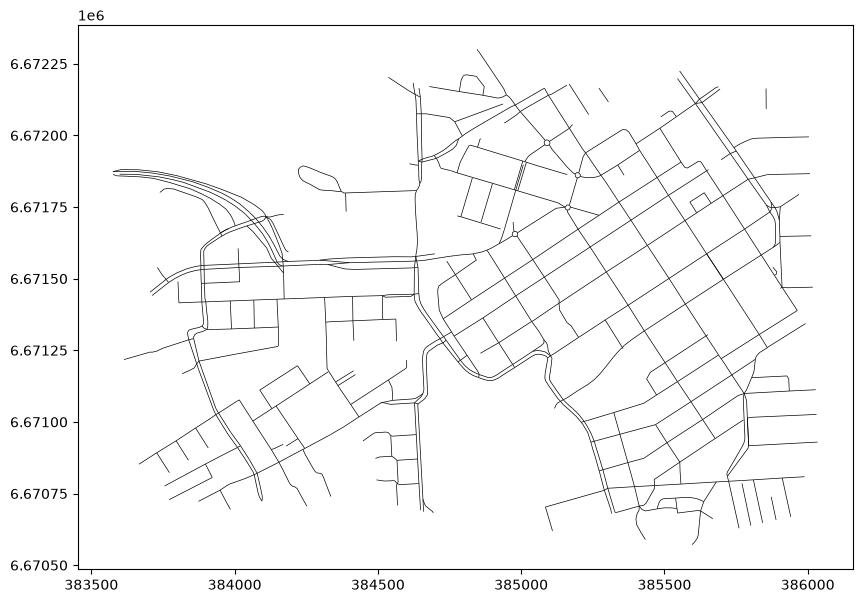

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import momepy
import neatnet
import networkx as nx

streets = gpd.read_file("data/digiroad_topology_errors.gpkg")
ax = streets.plot(color="black", linewidth=0.5, figsize=(10, 8))

_**Figure 8.X.** Street data for the Kamppi, Punavuori, Ruoholahti and Jätkäsaari districts of Helsinki, with some added topology errors._

As we can see, the errors are not visible on the map. To check the topology, we first convert the lines into a graph. In Chapter 8.1, we wrote our own function for this, but here we use the `gdf_to_nx()` function of the `momepy`[^momepy] library, which works in a similar manner: it uses the end points of the lines as nodes and the lines as edges. By default, the function creates an undirected `MultiGraph`, which keeps also the duplicate lines as separate edges. Then we check whether it is possible to travel between all parts of the network by counting its separate parts (called connected components) with the `nx.number_connected_components()` function. We will discuss connected components in more detail later in this section.

In [2]:
G_streets = momepy.gdf_to_nx(streets)
nx.number_connected_components(G_streets)

8

As we can see, the network consists of 8 separate parts. Some of them can be real, for instance short pieces of streets that were cut at the border of the area, but some of them can be caused by errors. To find the places where the errors may be located, let's look at the dead ends of the network, i.e. the nodes that are connected to only one edge (in other words, nodes whose degree is 1). The `momepy.node_degree()` function calculates the degree of every node and stores it as a node attribute, and the `momepy.nx_to_gdf()` function returns the nodes of the graph as a GeoDataFrame when we specify `lines=False`. Then we select the nodes whose degree is 1:

In [3]:
G_streets = momepy.node_degree(G_streets)
nodes = momepy.nx_to_gdf(G_streets, lines=False)
dead_ends = nodes.loc[nodes["degree"] == 1]
len(dead_ends)

103

Most of these dead ends are real, i.e. streets that end in a cul-de-sac or are cut at the border of the area. However, a dead end that is located very close to another street is suspicious, because it may be a gap or a missing node. Let's find the dead ends that have another street within 5 meters. We enlarge each dead end into a circle with a radius of 5 meters with the `.buffer()` method and count how many street segments intersect each circle with a spatial join (see Chapter 6.7). As each dead end touches its own street segment, the dead ends with more than one intersecting segment are close to another street. Finally, we plot all dead ends in black and the suspicious ones in red:

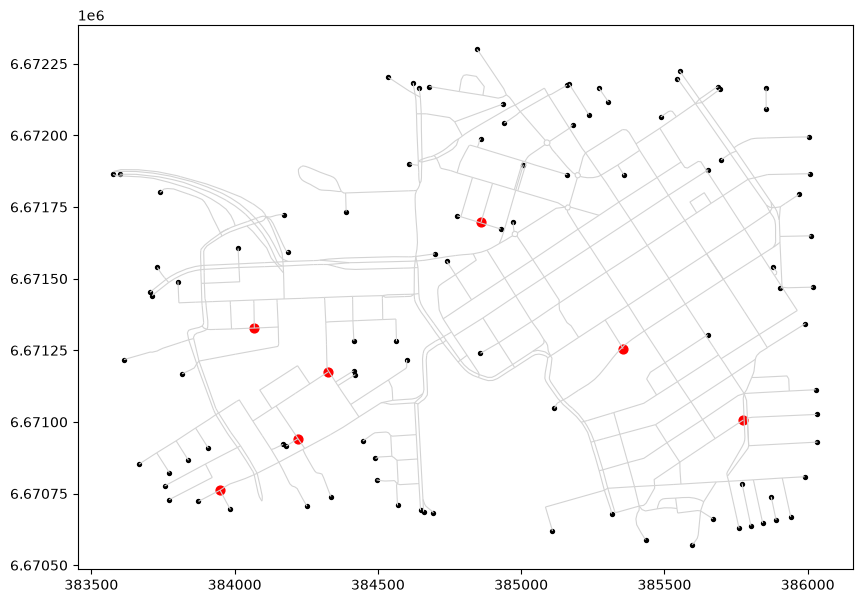

In [4]:
dead_end_areas = dead_ends.set_geometry(dead_ends.buffer(5))
nearby = gpd.sjoin(dead_end_areas, streets, predicate="intersects")
segment_counts = nearby.groupby(level=0).size()
suspicious = dead_ends.loc[segment_counts[segment_counts > 1].index]

ax = streets.plot(color="lightgrey", linewidth=0.8, figsize=(10, 8))
ax = dead_ends.plot(ax=ax, color="black", markersize=8)
ax = suspicious.plot(ax=ax, color="red", markersize=40)

_**Figure 8.X.** Dead ends of the street network (in black) and the dead ends that are located within 5 meters from another street (in red)._

Figure 8.X shows 7 suspicious dead ends. Six of them are the errors that we added to the data. The seventh one is an error that was already in our data: Sinebrychoffinkatu crosses Mallaskatu and ends a few meters past it (an overshoot), without a node at the crossing point. Next, let's check whether the data contain duplicate lines. We can find them with the `.duplicated()` method, which marks every row that is identical to some earlier row. Before the comparison, we convert the geometries into a standard form with the `.normalize()` method, so that the same line is detected as a duplicate even if its coordinates are stored in the opposite order:

In [5]:
duplicates = streets.geometry.normalize().duplicated()
streets.loc[duplicates]

,id,name,geometry
730,1733,Annankatu,"LINESTRING (385705.817 6671497.843, 385647.194..."
731,1317,Laivurinkatu,"LINESTRING (385794.028 6670916.935, 385789.424..."
732,1687,Salmisaarenkatu,"LINESTRING (383950.563 6671659.127, 383955.416..."


As we can see, three street segments are in the data twice. Finally, let's check whether there are lines that cross each other without a node at the crossing point. We can find them with a spatial join that uses the `"crosses"` predicate. Each pair of crossing lines is found twice (the first line crosses the second one and vice versa), so we divide the number of rows by two:

In [6]:
crossings = gpd.sjoin(streets, streets, predicate="crosses")
len(crossings) // 2

12

As we can see, there are 12 pairs of lines that cross each other without a node. However, not all of them are errors. For instance, streets that cross each other on different levels, such as a street on a bridge and a street below it, should not be connected. To tell whether a crossing is an error, we would need additional information, such as aerial images or attributes that tell whether a street is on a bridge or in a tunnel. Hence, we do not try to fix the crossings automatically.

Now that we have found the errors, let's fix them with the `neatnet`[^neatnet] library, which provides tools for cleaning street networks. The `neatnet.extend_lines()` function extends the loose ends of lines by at most the given distance (`tolerance`, here 5 meters) until they touch another line, which closes the gaps. The `neatnet.fix_topology()` function then adds a node to every place where the end of a line touches another line, which fixes the missing nodes. In addition, it removes duplicate lines and the nodes in which only two street segments meet (we will discuss such nodes later in this section):

In [7]:
streets_extended = neatnet.extend_lines(streets, tolerance=5)
streets_fixed = neatnet.fix_topology(streets_extended)

Let's check the result in the same way as above by counting the connected components, dead ends and duplicates of the fixed data:

In [8]:
G_fixed = momepy.node_degree(momepy.gdf_to_nx(streets_fixed))
nodes_fixed = momepy.nx_to_gdf(G_fixed, lines=False)

print("Connected components:", nx.number_connected_components(G_fixed))
print("Dead ends:", (nodes_fixed["degree"] == 1).sum())
print("Duplicates:", streets_fixed.geometry.normalize().duplicated().sum())

Connected components: 6
Dead ends: 97
Duplicates: 0


As we can see, the number of connected components decreased from 8 to 6, the number of dead ends decreased by six, and there are no duplicates left. The remaining six connected components were already in the original data. Let's zoom in to one of the suspicious dead ends and compare the data before and after the fix:

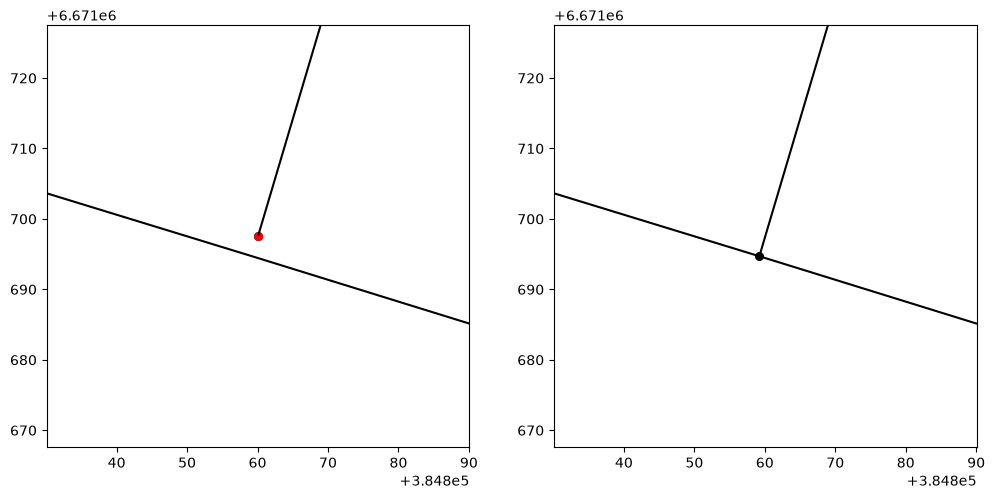

In [9]:
location = suspicious.geometry.iloc[0]
xmin, ymin, xmax, ymax = location.buffer(30).bounds

fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 6))
for ax, lines, points in [(ax1, streets, nodes), (ax2, streets_fixed, nodes_fixed)]:
    lines.plot(ax=ax, color="black")
    points.plot(ax=ax, color="black", markersize=30)
    points.loc[points["degree"] == 1].plot(ax=ax, color="red", markersize=30)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

_**Figure 8.X.** A gap between two streets before (left) and after (right) fixing the topology. The nodes are shown in black and the dead ends in red._

On the left, the side street ends before it reaches the street that it should join, and its end is a dead end. On the right, the side street has been extended to the other street, and there is a node where the two streets meet. Notice, however, that the overshoot at Sinebrychoffinkatu is still in the data, because the functions that we used do not shorten lines that continue past another line. Fixing it would require cutting the line at the crossing point and removing the part beyond it. In addition, `fix_topology()` merged the street segments that met at nodes of degree 2, which is why the fixed data contain 516 segments instead of 733. If the data had attributes that can change along a street, such as speed limits or the permitted driving direction, merging the segments could lose or mix such information. Hence, automatic fixes are useful, but it is always a good idea to check the result. The tolerance should also be chosen with care, because a too large tolerance could connect streets that are not connected in reality, such as a dead-end street that ends close to a motorway.

In the rest of this section, we use a drivable street network from OpenStreetMap. Let's retrieve it in the same way as in the previous section. This time, we use a slightly larger area that extends 3500 meters from the center point in each direction:

In [10]:
import osmnx as ox
import pandas as pd

center_point = (60.162, 24.937)
G = ox.graph_from_point(center_point, dist=3500, network_type="drive", simplify=False)

Now we have the street network stored in the variable `G` as a `MultiDiGraph`, just like in the previous section. Next, we will check whether it is possible to travel between all parts of this network.

## Connected components

One of the first things to check about a network is whether it is **connected**, i.e. whether it is possible to travel from any node of the network to any other node along the edges. A network that is not connected consists of several separate parts that are called **connected components** (a connected network has only one component). Within a connected component, every node can be reached from every other node, but it is not possible to travel from one component to another. For instance, an island without any road connection to the mainland forms its own connected component in a street network, like the island in the south-east corner of the street network data that we used in Chapter 8.1.

With directed graphs, such as our street network, connectivity can be defined in two ways. A directed graph is **weakly connected** if all of its nodes can be reached from each other when we ignore the directions of the edges, i.e. when we pretend that all streets could be traveled in both directions. A directed graph is **strongly connected** if all of its nodes can be reached from each other also when we follow the directions of the edges. For instance, a street network that has a one-way street leading to a dead end would be weakly connected, but not strongly connected, because there would be no way to drive out of the dead end. Correspondingly, a directed graph can be divided into weakly connected components and strongly connected components. Let's see how many of both our street network has:

In [11]:
print("Weakly connected components:", nx.number_weakly_connected_components(G))
print("Strongly connected components:", nx.number_strongly_connected_components(G))

Weakly connected components: 1
Strongly connected components: 324


As we can see, the network consists of only one weakly connected component. This is because `osmnx` keeps by default only the largest weakly connected component of the network when it retrieves the data (you can change this with the `retain_all` parameter). However, the network consists of several strongly connected components, which means that it is not possible to drive in both directions between all nodes of the network. A common reason for this is that we retrieved the data only for a limited area, which means that the streets are cut at the border of the area. If a one-way street leads out of the area, we can drive into the street from the rest of the network, but once we are on it, there is no way back, because the rest of the street is outside of our area (or the other way around, if the street leads into the area). Hence, each node along such a street forms a strongly connected component of its own.

Let's find the largest strongly connected component of the network and see how many nodes it contains. The `nx.strongly_connected_components()` function returns each component as a set (i.e. a collection of unique values) of node ids. We can find the largest component, i.e. the one with the most nodes, by using the built-in `max()` function of Python with the `key=len` argument, which compares the components based on their length, i.e. the number of nodes in them:

In [12]:
largest_component = max(nx.strongly_connected_components(G), key=len)

print("Nodes in the whole network:", G.number_of_nodes())
print("Nodes in the largest strongly connected component:", len(largest_component))

Nodes in the whole network: 17792
Nodes in the largest strongly connected component: 17348


As we can see, most of the nodes belong to the largest strongly connected component. To see where the other nodes are located, let's select the nodes that do not belong to the largest component and plot them in red on top of the street network. Here, we first extract the nodes and edges of the graph as `GeoDataFrames` like in the previous section. The index of the `nodes` GeoDataFrame contains the node ids, and we can use the `.isin()` method to check which of them are part of the largest component (the `~` character reverses the selection):

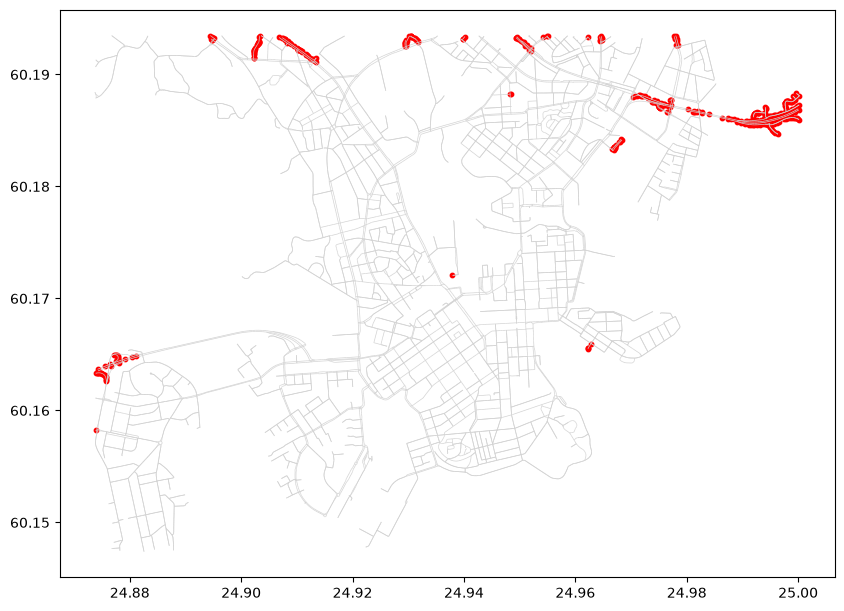

In [13]:
nodes, edges = ox.graph_to_gdfs(G)
outside_nodes = nodes.loc[~nodes.index.isin(largest_component)]

ax = edges.plot(color="lightgrey", linewidth=0.5, figsize=(10, 10))
ax = outside_nodes.plot(ax=ax, color="red", markersize=10)

_**Figure 8.X.** Nodes that do not belong to the largest strongly connected component of the street network (in red)._

The red nodes on the map show the places where it is not possible to drive both to and from the rest of the network. Typically, they are located along one-way streets near the border of the area, as discussed above, but they can also be caused, for example, by a one-way street that leads to a dead end. Let's test what happens if we try to find a route between one of these nodes and a node that belongs to the largest component. We can check whether a route exists between two nodes with the `nx.has_path()` function:

In [14]:
node_outside = outside_nodes.index[0]
node_inside = list(largest_component)[0]

print("Route from outside to inside:", nx.has_path(G, node_outside, node_inside))
print("Route from inside to outside:", nx.has_path(G, node_inside, node_outside))

Route from outside to inside: False
Route from inside to outside: True


As we can see, at least one of the two routes does not exist, i.e. we cannot drive between these two nodes in both directions. If we tried to find such a route with the `nx.dijkstra_path()` function that we used in the previous section, `networkx` would raise an error. For this reason, it is common to keep only the largest strongly connected component of the network for routing and other network analyses. With `osmnx`, we can do this with the `ox.truncate.largest_component()` function by setting the `strongly` parameter to `True`:

In [15]:
G = ox.truncate.largest_component(G, strongly=True)
print("Number of nodes:", G.number_of_nodes())

Number of nodes: 17348


As we can see, the number of nodes is now the same as the number of nodes in the largest strongly connected component above. Our graph now only keeps the nodes and edges that can be reached from every part of the network, which means that we can drive from every node to every other node.

## Node degree

Next, let's look at how many edges are connected to each node of our network. The **degree** of a node is the number of edges that are connected to it. In a street network, the degree tells how many street segments (i.e. parts of streets between two nodes) meet at a node. For instance, a node with degree 1 is a dead end, a node with degree 3 is an intersection where three street segments meet (such as a T-junction), and a node with degree 4 is an intersection of four street segments (such as a crossroads).

When calculating the degree, we need to be careful with directed graphs. As we learned in Chapter 8.1, a street that can be traveled in both directions is represented in a directed graph with two edges, one for each direction (called reciprocal edges). Hence, if we calculated the degree directly from our directed graph, each two-way street would be counted twice. To count each street segment only once, we first convert our graph into an undirected graph with the `ox.convert.to_undirected()` function:

In [16]:
G_undirected = ox.convert.to_undirected(G)

Now we can get the degree of every node with the `.degree()` method of the graph, which returns pairs of node ids and degrees. Let's add the degrees as a new column to the `nodes` GeoDataFrame. As our graph has changed, we first extract the nodes and edges from the graph again. Then we convert the degrees into a dictionary and further into a `pandas` `Series` that uses the node ids as its index, which makes it possible to match the degrees with the correct nodes (as we did with the travel times in the previous section). Finally, we count how many nodes have each degree value (sorted by the degree):

In [17]:
nodes, edges = ox.graph_to_gdfs(G)
nodes["degree"] = pd.Series(dict(G_undirected.degree()))
nodes["degree"].value_counts().sort_index()

degree
1      220
2    15617
3      988
4      506
5       16
6        1
Name: count, dtype: int64

As we can see, a large share of the nodes have a degree of 2. These nodes are not intersections at all, but points in the middle of a street where the street simply continues from one edge to the next. They are part of our network because we retrieved the data with `simplify=False`, which keeps all the points that were used to draw the streets in OpenStreetMap. The nodes with degree 1 are either dead ends or places where a street was cut at the border of the area, and the nodes with degree 3 or more are intersections. Let's see where these nodes are located by plotting them on a map, colored by their degree:

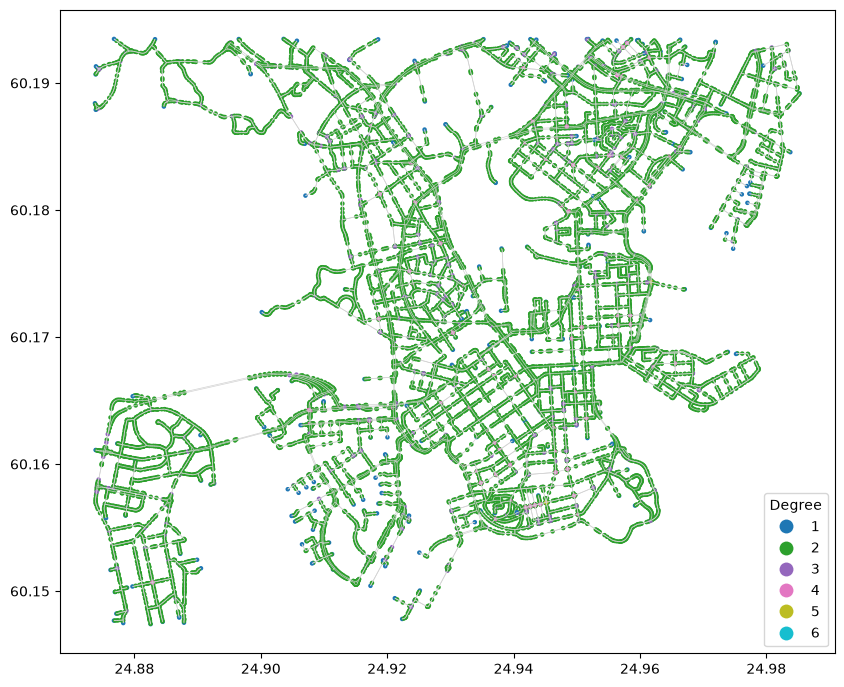

In [18]:
ax = edges.plot(color="lightgrey", linewidth=0.5, figsize=(10, 10))
ax = nodes.plot(
    ax=ax,
    column="degree",
    categorical=True,
    cmap="tab10",
    markersize=5,
    legend=True,
    legend_kwds={"title": "Degree"},
)

_**Figure 8.X.** Nodes of the street network colored by their degree._

As we can see, the nodes with degree 2 are spread along the streets all over the network. Because these nodes are not real intersections, they do not tell much about the structure of the street network, but they make the network larger than necessary. Next, we will see how we can clean the network from such nodes.

## Simplifying the network

The nodes with degree 2 are not errors as such, but they are unnecessary for many analyses. Another common issue in street networks is that a single intersection is represented with several nodes, which typically happens when the two driving directions of a large street are drawn as separate lines in the data. For fixing this issue, `osmnx` has the `ox.consolidate_intersections()` function that merges nodes that are close to each other into a single node, but we do not use it in this section.

We can clean the network by merging all the street elements that are between two intersections into one. This process is called **simplification**, and it is the same step that `pyrosm` did for us automatically in the previous section, and that the `fix_topology()` function of `neatnet` did for the Digiroad data at the beginning of this section. With `osmnx`, we can do it with the `ox.simplify_graph()` function. The function removes the nodes that are only in the middle of a street and merges the edges connected to them into a single edge. Notice that the shape of the streets is not lost in this process, because `osmnx` stores the shape of the merged edges as a `LineString` in the `geometry` attribute of the new edge. Let's simplify our graph and compare the number of nodes and edges before and after the simplification:

In [19]:
G_simplified = ox.simplify_graph(G)

print("Nodes before simplification:", G.number_of_nodes())
print("Nodes after simplification:", G_simplified.number_of_nodes())
print("Edges before simplification:", G.number_of_edges())
print("Edges after simplification:", G_simplified.number_of_edges())

Nodes before simplification: 17348
Nodes after simplification: 1773
Edges before simplification: 27866
Edges after simplification: 3985


As we can see, the simplification removed most of the nodes and edges from the network. This is in line with what we found when we calculated the degrees: most of the nodes had a degree of 2, i.e. they were not real intersections. Let's visualize the difference by plotting the nodes of the network before and after the simplification next to each other:

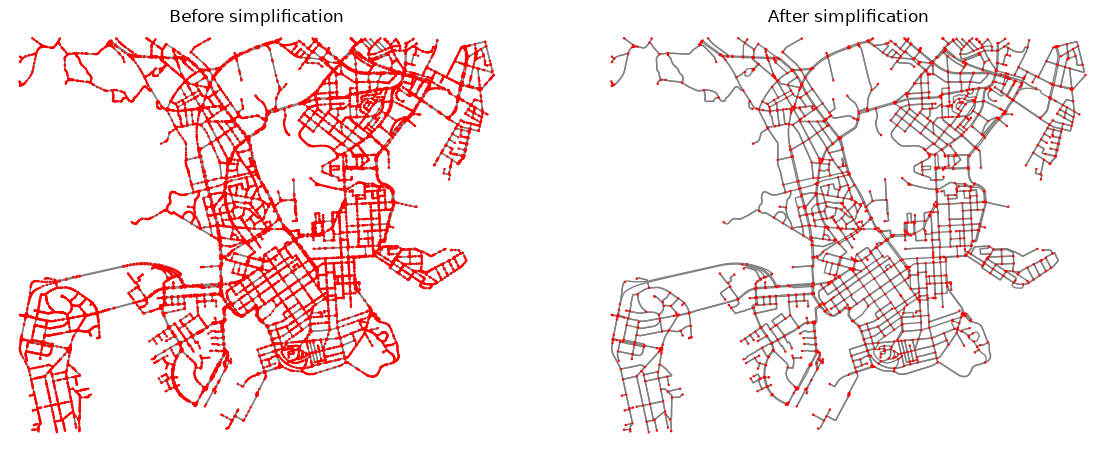

In [20]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 7))

ox.plot_graph(
    G,
    ax=ax1,
    node_size=3,
    node_color="red",
    edge_color="grey",
    bgcolor="white",
    show=False,
)
ax1.set_title("Before simplification")

ox.plot_graph(
    G_simplified,
    ax=ax2,
    node_size=3,
    node_color="red",
    edge_color="grey",
    bgcolor="white",
    show=False,
)
ax2.set_title("After simplification");

_**Figure 8.X.** Nodes of the street network before (left) and after (right) the simplification._

As we can see, after the simplification the nodes are mainly located at the intersections and at the ends of the streets. Now the nodes of our network describe the actual structure of the street network, and the network is also smaller, which makes the analyses faster. We will use this simplified network in the rest of this section.

## Centrality

So far, we have looked at the structure of the network. Next, we want to find out which nodes and edges are the most important ones in the network. For instance, a street can be important because many routes go through it, and an intersection can be important because it is close to all other places in the network. In network analysis, the importance of a node or an edge is measured with **centrality** measures. There is no single definition of what makes a node important, and hence there are many different centrality measures that look at importance from different perspectives. In the following, we go through three commonly used measures using our simplified network: degree centrality, betweenness centrality and closeness centrality. You can read the Wikipedia article about different centrality measures[^centrality] if you are interested what the other centrality measures mean.

### Degree centrality

**Degree centrality** is a simple centrality measure that counts how many neighbors a node has, i.e. how many other nodes it is directly connected to. To make the values comparable between networks of different sizes, the degree is divided by the number of other nodes in the network, which means that degree centrality tells the fraction of nodes that a node is connected to. Let's calculate the degree centrality with the `nx.degree_centrality()` function. As with the degree, we use an undirected version of our simplified network, so that each street segment is counted only once. We also extract the nodes and edges of the simplified network as GeoDataFrames and add both the degree and the degree centrality of each node to them, so that we can compare the two. To keep the output short, we show only one node for each value of the degree:

In [21]:
G_simplified_undirected = ox.convert.to_undirected(G_simplified)

nodes_simplified, edges_simplified = ox.graph_to_gdfs(G_simplified)
nodes_simplified["degree"] = pd.Series(dict(G_simplified_undirected.degree()))
nodes_simplified["degree_centrality"] = pd.Series(
    nx.degree_centrality(G_simplified_undirected)
)
degrees = nodes_simplified[["degree", "degree_centrality"]]
degrees.drop_duplicates("degree").sort_values("degree")

,degree,degree_centrality
osmid,,
25470397,1,0.000564
25198522,2,0.001129
132105,3,0.001693
25198968,4,0.002257
25344880,5,0.002822
247359926,6,0.003386


As we can see, degree centrality is directly related to the degree: a node with degree 2 has twice the degree centrality of a node with degree 1, a node with degree 3 has three times as much, and so on. Hence, within a single network, degree centrality shows the same pattern as the degree itself, and it is mainly useful when we want to compare networks of different sizes.

### Betweenness centrality

**Betweenness centrality** measures how often a node or an edge lies on the shortest paths between all pairs of nodes in the network. In a street network, the streets with high betweenness centrality are the ones that many of the shortest routes go through, such as main streets that connect different parts of the city. Let's calculate the betweenness centrality for each edge of our network with the `nx.edge_betweenness_centrality()` function (the `nx.betweenness_centrality()` function does the same for nodes). We use the length of the edges as the weight, so that the shortest paths are based on distance. Notice that this calculation can take a while, because the function needs to find the shortest paths between all pairs of nodes in the network:

In [22]:
edge_betweenness = nx.edge_betweenness_centrality(G_simplified, weight="length")
edges_simplified["betweenness"] = pd.Series(edge_betweenness)

As a result, we get a dictionary in which each edge is identified by its `u`, `v` and `key` values (the same values that `osmnx` uses as the index of the edges, as we saw in the previous section), and the values are the betweenness centralities of the edges. We added these values as a new column to the `edges_simplified` GeoDataFrame in the same way as we did with the degrees. Because our graph is directed, the shortest paths follow the allowed driving directions. Now we can plot the streets on a map and color them by their betweenness centrality:

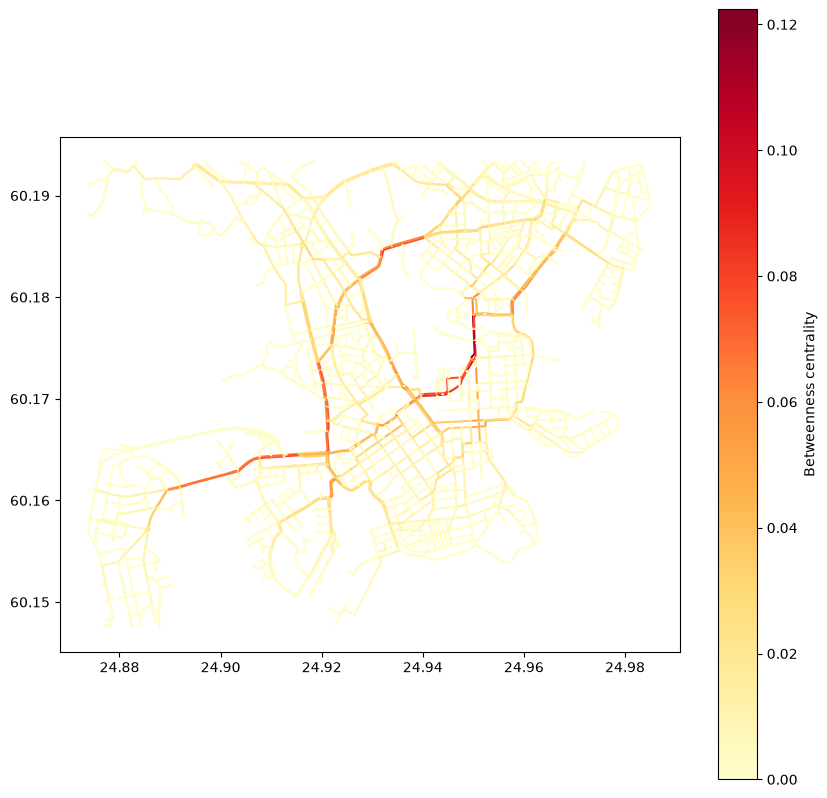

In [23]:
ax = edges_simplified.plot(
    column="betweenness",
    cmap="YlOrRd",
    linewidth=1.5,
    figsize=(10, 10),
    legend=True,
    legend_kwds={"label": "Betweenness centrality"},
)

_**Figure 8.X.** Betweenness centrality of the streets in the Helsinki city centre._

In the map, the streets with high betweenness centrality (in dark red) are the ones that many of the shortest routes between different parts of the area pass through, whereas the light yellow streets are rarely part of the shortest routes between other places. Typically, the streets with the highest values are main streets, because they connect different parts of the city.

### Closeness centrality

**Closeness centrality** measures how easily a node can be reached from all other nodes in the network. It is based on the average shortest path distance from all other nodes to the node: the shorter the average distance, the higher the closeness centrality. Let's calculate the closeness centrality for each node with the `nx.closeness_centrality()` function. Here, the `distance` parameter tells which edge attribute to use as the distance between the nodes:

In [24]:
closeness = nx.closeness_centrality(G_simplified, distance="length")
nodes_simplified["closeness"] = pd.Series(closeness)

As a result, we get a dictionary with the closeness centrality of each node, which we added as a new column to the `nodes_simplified` GeoDataFrame in the same way as the degree centrality. The closeness centrality is calculated as one divided by the average distance to the node. Because our distances are in meters, the values are very small numbers, and hence they are mainly useful for comparing the nodes with each other. Let's plot the nodes on a map and color them by their closeness centrality:

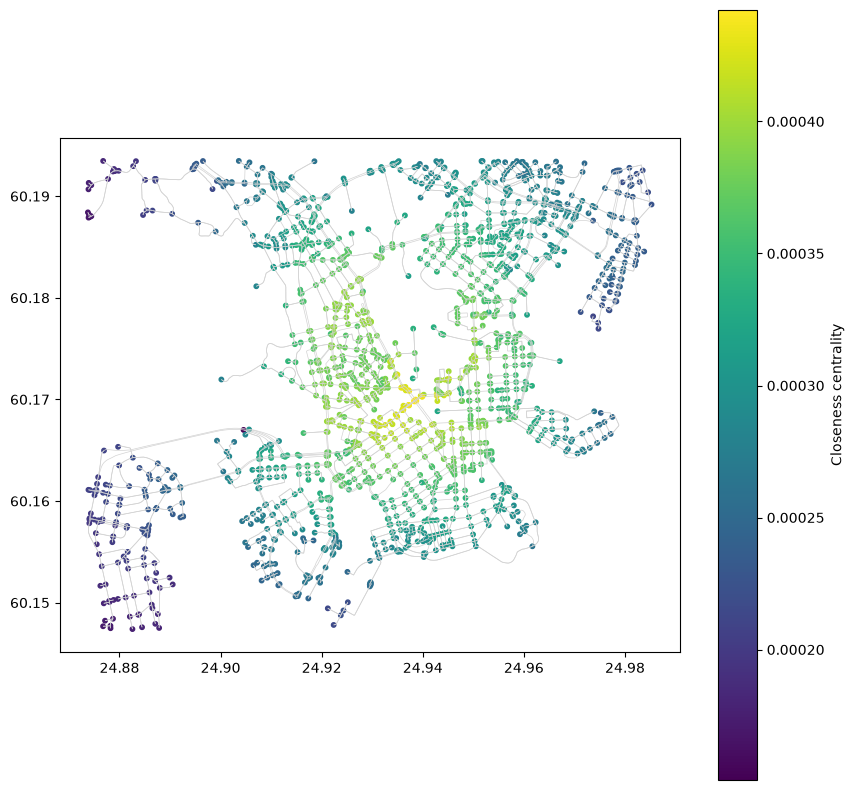

In [25]:
ax = edges_simplified.plot(color="lightgrey", linewidth=0.5, figsize=(10, 10))
ax = nodes_simplified.plot(
    ax=ax,
    column="closeness",
    cmap="viridis",
    markersize=10,
    legend=True,
    legend_kwds={"label": "Closeness centrality"},
)

_**Figure 8.X.** Closeness centrality of the nodes in the street network._

As we can see, closeness centrality is highest in the central parts of the street network and decreases towards its edges. This is natural, as the nodes in the central parts are on average closer to all other nodes. However, part of this pattern is caused by the fact that our data ends at the border of the area, whereas in reality the street network continues beyond it. This kind of distortion at the borders of a study area is called an *{term}`edge effect`*, and it is good to keep it in mind when interpreting centrality measures (betweenness centrality is affected by it as well).

## Other types of networks

Thus far in this chapter, we have used networks to represent streets. However, networks are used for many other purposes in GIS as well. For instance, in spatial statistics, the neighbor relationships between areas, such as which neighborhoods share a border, are often represented as a graph (called spatial weights), and in urban studies, network measures such as the node degree are used to compare the street patterns of different cities. In addition, many phenomena form networks themselves, and the network operations that we have learned so far can be applied to them in a similar manner as to streets. In the following, we look at two examples: a river network and an electricity grid. We retrieve both of them from OpenStreetMap with the `pyrosm` library that we introduced in the previous section, because our examples cover large areas. In OpenStreetMap, the type of each feature is described with **tags**, which are key-value pairs such as `highway=residential` for a residential street or `waterway=river` for a river[^osm_tags]. With `pyrosm`, we can retrieve any type of line features as a network by passing a custom filter to the `get_network()` method. The filter tells which tags the features should have, and it is written in a similar format as the queries of the Overpass API, e.g. `'["waterway"="river"]'` for rivers.

### River networks

Rivers form natural networks in which smaller rivers (tributaries) join larger ones, and the water flows from upstream to downstream. Let's examine the rivers in Acre, a state in the western part of the Brazilian Amazon, where the rivers are known for their winding courses. We download the data with the `get_data_by_geocoding()` function that we used in the previous section, and select the rivers with a custom filter that keeps only the features tagged with `waterway=river`. We also keep the names of the rivers as a column with the `extra_attributes` parameter:

/Users/tenkanh2/.local/lib/python3.12/site-packages/pyrosm/data/extract_index.py:925: UserWarning: Movisda BR-AC leaves out 85 km² (0.052 %) of the area. This part lies within the bounds [-73.983, -11.148, -66.624, -7.113].
  warnings.warn(


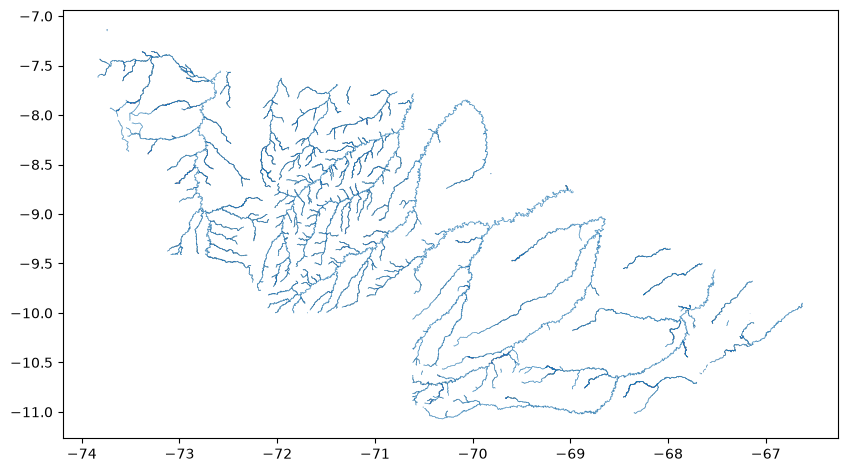

In [26]:
from pyrosm import OSM, get_data_by_geocoding
import geopandas as gpd
import shapely

fp_acre = get_data_by_geocoding("Acre, Brazil")
osm_acre = OSM(fp_acre)
river_nodes, rivers = osm_acre.get_network(
    custom_filter='["waterway"="river"]', nodes=True, extra_attributes=["name"]
)
ax = rivers.plot(linewidth=0.5, figsize=(10, 8))

_**Figure 8.X.** Rivers in the state of Acre in Brazil, based on OpenStreetMap data._

As we can see, Acre is covered by a dense network of rivers. Similarly as in the previous section, `pyrosm` also printed a warning above the figure, because the downloaded PBF file does not cover the whole boundary polygon of Acre, and hence a small part of the area is missing from our data. In this case, the missing part is less than 0.1 % of the area and consists mostly of narrow strips along the border of the state, which does not affect our analysis.

A common way to describe the shape of a river is its **sinuosity**[^sinuosity], which is the length of the river divided by the straight-line distance between its end points. A completely straight river has a sinuosity of 1, and the more the river winds, the higher its sinuosity. Rivers with a sinuosity above 1.5 are typically called meandering rivers.

Similarly to the street network in the previous section, each river in our data is split into many short segments. To calculate the sinuosity of each river, we first need to combine the segments of each river into a single line. We can do this by dissolving the segments based on the name of the river (see Chapter 6.3) and joining the resulting lines together with the `shapely.line_merge()` function. Before this, we reproject the data into a UTM coordinate reference system with the `.estimate_utm_crs()` method, so that the lengths are in meters:

In [27]:
crs_acre = rivers.estimate_utm_crs()
named_rivers = rivers.dropna(subset=["name"]).to_crs(crs_acre).dissolve(by="name")
named_rivers["geometry"] = shapely.line_merge(named_rivers.geometry)
named_rivers.geom_type.value_counts()

LineString         105
MultiLineString     24
Name: count, dtype: int64

As a result, most of the rivers are now represented as a single `LineString`. However, some of the rivers consist of several separate parts (`MultiLineString`), for instance because a part of the river flows outside of Acre. For these rivers, we use the longest part when calculating the sinuosity. Let's create a function that calculates the sinuosity of a line, apply it to all rivers, and list the five longest rivers in our data:

In [28]:
def calculate_sinuosity(line):
    """Returns the length of a line divided by the distance between its end points."""
    if line.geom_type == "MultiLineString":
        line = max(line.geoms, key=lambda part: part.length)
    start = shapely.Point(line.coords[0])
    end = shapely.Point(line.coords[-1])
    return line.length / start.distance(end)


named_rivers["sinuosity"] = named_rivers.geometry.apply(calculate_sinuosity)
named_rivers["length_km"] = named_rivers.length / 1000
longest_rivers = named_rivers.sort_values("length_km", ascending=False)
longest_rivers[["length_km", "sinuosity"]].head()

,length_km,sinuosity
name,,
Río Acre,793.145283,2.196499
Rio Envira,647.821961,2.188701
Rio Tarauacá,572.878486,2.111082
Rio Juruá,461.409124,2.214850
Rio Purus,445.682569,2.426568


As we can see, the sinuosity of the largest rivers in Acre is roughly 2, which means that the rivers are about twice as long as the straight-line distance between their end points. Hence, all of them are clearly meandering rivers. Notice that we only calculated the sinuosity for the parts of the rivers that are located in Acre, because our data ends at the border of the state.

Next, let's use our river data as a network. Water flows only in one direction, and hence rivers form a directed network (as we mentioned in Chapter 8.1). In OpenStreetMap, rivers are drawn in the direction of the flow, which means that the `u` and `v` columns of our data tell from which node to which node the water flows in each segment. Hence, we can build a directed graph from the river segments with the `nx.from_pandas_edgelist()` function, which creates a graph from a table in which each row represents an edge:

In [29]:
G_river = nx.from_pandas_edgelist(
    rivers, source="u", target="v", create_using=nx.MultiDiGraph
)

With the directed graph, we can find out, for instance, which parts of the river network are located upstream of a given location. This kind of information is useful, e.g. when assessing where floodwater or pollution could come from (the area from which water flows to a given location is called a watershed, which we will discuss in Chapter 12). Let's find the upstream river network of Cruzeiro do Sul, a city located on the bank of the Juruá river. We first find the node of the river network that is closest to the city and then use the `nx.ancestors()` function that returns all nodes from which there is a path to the given node:

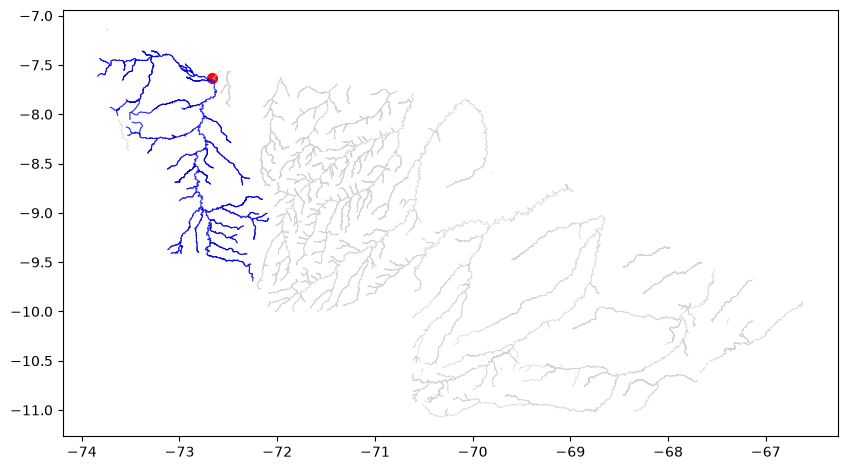

In [30]:
city = gpd.GeoSeries([shapely.Point(-72.669, -7.636)], crs="EPSG:4326")
distances = river_nodes.to_crs(crs_acre).distance(city.to_crs(crs_acre).iloc[0])
city_node = river_nodes.loc[distances.idxmin(), "id"]

upstream_nodes = nx.ancestors(G_river, city_node)
upstream_rivers = rivers.loc[rivers["u"].isin(upstream_nodes)]

ax = rivers.plot(color="lightgrey", linewidth=0.5, figsize=(10, 8))
ax = upstream_rivers.plot(ax=ax, color="blue", linewidth=0.8)
ax = city.plot(ax=ax, color="red", markersize=50)

_**Figure 8.X.** The rivers upstream of Cruzeiro do Sul (in blue), and the location of the city (in red)._

The blue rivers in Figure 8.X show the parts of the river network from which the water flows past Cruzeiro do Sul. As we can see, they cover a large part of western Acre. Notice that the Juruá river starts in Peru, which means that the actual upstream network of the city is larger than what we can see in our data. This is another example of the edge effect that we discussed earlier in this section.

### Power grids

Electricity is delivered from power plants to consumers through a network of power lines. The lines meet at **substations**, where the electricity is, for instance, transformed from one voltage to another and distributed to the connected lines. The power lines with the highest voltages form the transmission grid that carries electricity over long distances. A power grid is vulnerable if the failure of a single power line, e.g. due to a storm, can cut off a part of the grid from the rest of it. Hence, grid operators aim to build grids in which there is an alternative route for the electricity, if one line fails.

Let's examine the transmission grid of Iceland, which is an island with its own power grid that is not connected to other countries. We retrieve the power lines with a custom filter that keeps the features whose `power` tag contains either `line` or `cable` (the `~` character means that the value is matched as a text pattern, and the `|` character means "or"). We also keep the names and voltages of the lines. The voltages are stored in volts as text, so we convert them into numbers and keep only the lines with a voltage of at least 66 000 volts (66 kV), which belong to the transmission grid:

/Users/tenkanh2/.local/lib/python3.12/site-packages/pyrosm/data/extract_index.py:925: UserWarning: Movisda IS leaves out 1.5e+02 km² (0.085 %) of the area. This part lies within the bounds [-25.014, 63.086, -12.805, 67.353].
  warnings.warn(


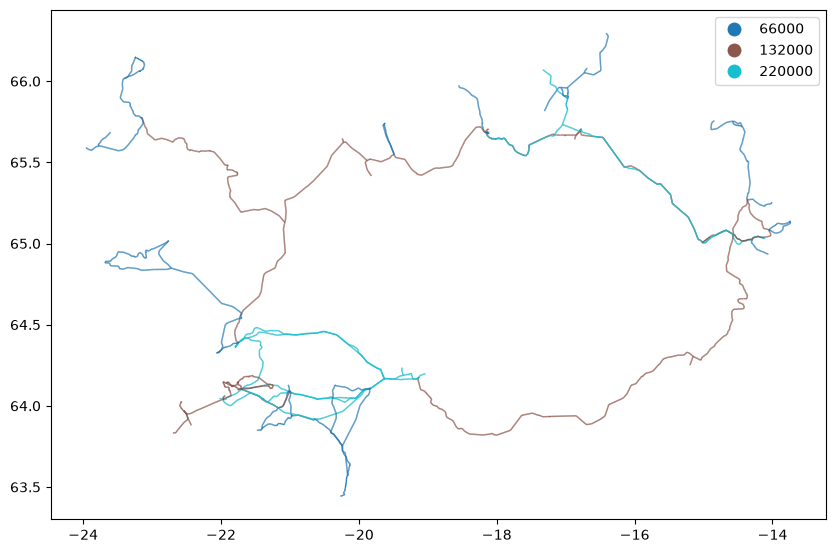

In [31]:
fp_iceland = get_data_by_geocoding("Iceland")
osm_iceland = OSM(fp_iceland)
grid_nodes, power_lines = osm_iceland.get_network(
    custom_filter='["power"~"line|cable"]',
    nodes=True,
    extra_attributes=["name", "voltage"],
)
power_lines["voltage"] = pd.to_numeric(power_lines["voltage"], errors="coerce")
power_lines = power_lines.loc[power_lines["voltage"] >= 66000]
power_lines["voltage"] = power_lines["voltage"].astype(int)

ax = power_lines.plot(
    column="voltage", categorical=True, legend=True, linewidth=1, figsize=(10, 7)
)

_**Figure 8.X.** The transmission grid of Iceland colored by the voltage of the power lines (in volts)._

Before we can analyze the grid as a network, we need to fix one topology issue in the data. In a power grid, the lines are connected to each other at substations. However, in OpenStreetMap, the substations are typically drawn as separate areas, and the lines that lead to the same substation end at different points inside or next to it. Hence, these lines do not share any node, and a graph created directly from them would consist of many separate pieces. To fix this, we read the substations with the `get_data_by_custom_criteria()` method and enlarge their areas by 50 meters with the `.buffer()` method. Then, we find the nodes of the power lines that are located within these areas with a spatial join (see Chapter 6.7). Finally, we replace the ids of these nodes in the `u` and `v` columns with the id of the substation, which connects all lines that lead to the same substation to each other. Segments that start and end at the same substation are removed:

In [32]:
substations = osm_iceland.get_data_by_custom_criteria(
    custom_filter={"power": ["substation"]}, extra_attributes=["name"]
)
crs_iceland = power_lines.estimate_utm_crs()
substation_areas = substations[["id", "name", "geometry"]].to_crs(crs_iceland)
substation_areas["geometry"] = substation_areas.buffer(50)

nodes_in_substations = gpd.sjoin(
    grid_nodes[["id", "geometry"]].to_crs(crs_iceland),
    substation_areas,
    predicate="within",
).drop_duplicates("id_left")
node_to_substation = dict(
    zip(nodes_in_substations["id_left"], nodes_in_substations["id_right"])
)

power_lines["u"] = power_lines["u"].replace(node_to_substation)
power_lines["v"] = power_lines["v"].replace(node_to_substation)
power_lines = power_lines.loc[power_lines["u"] != power_lines["v"]]

Now we can build a graph from the power lines in the same way as we did with the rivers. This time, we create an undirected graph, because electricity can flow along a power line in both directions. We also store the names of the lines as an edge attribute, and check how many connected components our grid has:

In [33]:
G_grid = nx.from_pandas_edgelist(
    power_lines, source="u", target="v", edge_attr="name", create_using=nx.MultiGraph
)
print("Connected components:", nx.number_connected_components(G_grid))

Connected components: 4


As we can see, our grid still consists of a few separate pieces. These are short pieces of power lines that are not connected to any substation in the data, for instance because a part of the line is missing in OpenStreetMap. Similarly as with the street network earlier in this section, we keep only the largest connected component for the analysis:

In [34]:
G_grid = G_grid.subgraph(max(nx.connected_components(G_grid), key=len)).copy()

Now we can find out which power lines are critical for the grid. An edge whose removal splits a network into two separate parts is called a **bridge**. In a power grid, the bridges are lines without any backup: if such a line fails, all substations behind it lose their connection to the rest of the grid. We can find the bridges with the `nx.bridges()` function, which returns the bridges as pairs of nodes. Let's mark the segments of the power lines that are bridges and plot them in red on top of the grid:

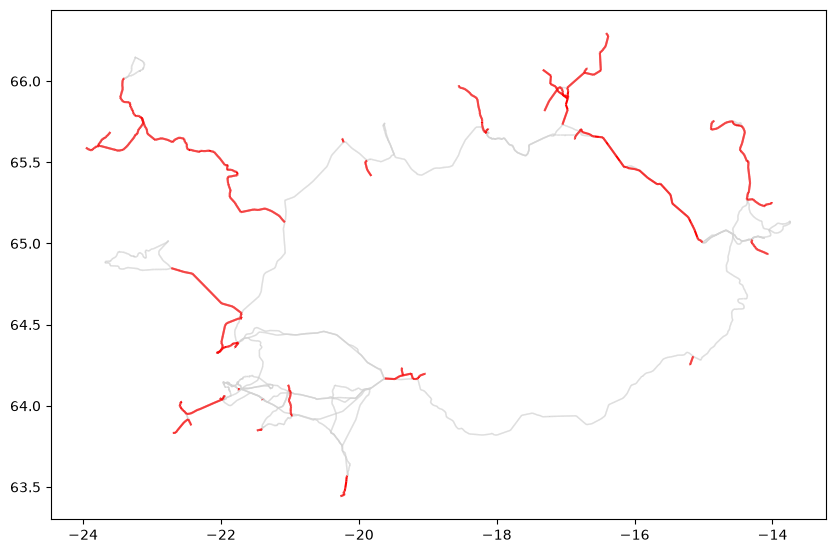

In [35]:
bridges = set(nx.bridges(G_grid))
power_lines["bridge"] = [
    (u, v) in bridges or (v, u) in bridges
    for u, v in zip(power_lines["u"], power_lines["v"])
]

ax = power_lines.plot(color="lightgrey", linewidth=1, figsize=(10, 7))
ax = power_lines.loc[power_lines["bridge"]].plot(ax=ax, color="red", linewidth=1.5)

_**Figure 8.X.** The power lines of the transmission grid of Iceland that are bridges (in red), i.e. lines whose failure would cut off a part of the grid._

As we can see, a large part of the grid forms loops, in which the electricity can take an alternative route if one line fails. However, several parts of the grid are connected to the rest of it through a single line. Let's test what would happen if one of these lines, Glerárskógalína 1, failed. This line connects the Westfjords region in the northwest of Iceland to the rest of the grid. We remove all edges of the line from a copy of our graph, find the largest connected component that remains, and list the substations that are no longer part of it:

In [36]:
G_failure = G_grid.copy()
failed_line = [
    (u, v, key)
    for u, v, key, name in G_grid.edges(keys=True, data="name")
    if name == "Glerárskógalína 1"
]
G_failure.remove_edges_from(failed_line)
main_grid = max(nx.connected_components(G_failure), key=len)

grid_substations = substation_areas.loc[substation_areas["id"].isin(G_grid.nodes)]
cut_off = grid_substations.loc[~grid_substations["id"].isin(main_grid)]
cut_off["name"].dropna().tolist()

['Geiradalur',
 'Glerárskógar',
 'Breiðidalur',
 'Mjólká',
 'Keldeyri',
 'Ísafjörður',
 'Bolungarvík']

As we can see, the failure of this single line would cut off several substations from the main grid, including the substation of Ísafjörður, the largest town in the Westfjords. In practice, local power plants in the region could still produce part of the electricity, but the region would lose its connection to the rest of the grid. This kind of analysis is a simple way to find the weak points of a network, and the same approach can be applied to other networks as well, such as street networks or water pipes. Notice, however, that the results depend on how completely and accurately the grid has been mapped in OpenStreetMap, and hence they do not necessarily match the official data of the grid operator.

In this section, we learned how to check whether a network is connected, how to calculate the degree of the nodes, how to clean a street network by simplifying it, how to measure the importance of nodes and edges with centrality measures, and how to apply these ideas to other types of networks, such as rivers and power grids. Public transport routes and stops form networks as well, and they can be combined with street networks. In the next section, we will move on to such multimodal networks that combine several modes of transport, such as walking and public transport.

## Footnotes

[^networkx]: <https://networkx.org/documentation/stable/>
[^osmnx]: <https://osmnx.readthedocs.io/en/stable/>
[^momepy]: <https://docs.momepy.org/>
[^neatnet]: <https://uscuni.org/neatnet/>
[^centrality]: <https://en.wikipedia.org/wiki/Centrality>
[^osm_tags]: <https://wiki.openstreetmap.org/wiki/Tags>
[^sinuosity]: <https://en.wikipedia.org/wiki/Sinuosity>